# Évaluation du modèle : base vs LoRA (jeu de test)

On compare le modèle de base (`Qwen2.5-1.5B-Instruct`, sans adaptation) et le(s) adaptateur(s) LoRA sur `datasets/test.json`.

**Ce qu'on mesure : uniquement le contenu de la dernière réponse de l'assistant.**
Pour chaque exemple du test, le modèle reçoit tout ce qui précède (system + historique, avec le chat template de Qwen) et on regarde ce qu'il produit pour le dernier message `assistant`, comparé à celui du dataset.

| Métrique | Calcul | Équivalent W&B / SFTTrainer |
|---|---|---|
| **Loss** | entropie croisée moyenne par token, *teacher forcing*, sur les tokens du **contenu** de la dernière réponse | `eval/loss` |
| **Perplexité** | `exp(loss)` | (dérivée) |
| **Token accuracy** | % de tokens où `argmax(logits)` = token attendu (teacher forcing, même tokens que la loss) | `eval/mean_token_accuracy` |
| **F1 par type** | F1 sur les mots entre la réponse **générée** (greedy) et la réponse du dataset, moyenné par type (`action.valide`, `fin`, …) | — |

Choix volontaires :
- Les tokens du chat template (`<|im_start|>assistant`, `<|im_end|>`…) sont **exclus** : on ne juge pas le formatage, seulement le texte de la réponse.
- Les **types** ne sont jamais donnés au modèle (seuls `role` et `content` passent). Ils servent uniquement à regrouper les résultats pour l'analyse.
- On ne cherche pas à produire un JSON : on compare uniquement le `content`.

## 0. Installation

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip uninstall -q -y torchao
    %pip install -q -U transformers peft accelerate pandas matplotlib

## 1. Chemins du projet

In [2]:
import os, sys, json, math, re, random, subprocess
from collections import Counter
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/2ec3/NLP_narrative-game.git"
BRANCH = None   # ← nom de ta branche si besoin (None = branche par défaut)

if IN_COLAB:
    PROJECT_ROOT = Path("/content/NLP_narrative-game")
    if not PROJECT_ROOT.exists():
        cmd = ["git", "clone"] + (["-b", BRANCH] if BRANCH else []) + [REPO_URL, str(PROJECT_ROOT)]
        subprocess.run(cmd, check=True)
else:
    current = Path.cwd().resolve()
    PROJECT_ROOT = next((p for p in [current, *current.parents] if (p / "datasets").is_dir()), None)
    if PROJECT_ROOT is None:
        raise FileNotFoundError(f"Pas de dossier datasets/ trouvé depuis {current}. Lance le notebook depuis le projet.")

os.chdir(PROJECT_ROOT)
print("Racine du projet :", PROJECT_ROOT)

Racine du projet : /content/NLP_narrative-game


## 2. Configuration

- `ADAPTERS` : un ou plusieurs adaptateurs LoRA à comparer au modèle de base (nom affiché → dossier). Ajoute une ligne par adaptateur (ex. r=4 et r=8).
- Si l'adaptateur est sur Google Drive (cf. `Training.ipynb`), mets son chemin, par ex. `/content/drive/MyDrive/GameMasterTraining/best_gm_adapter` (après `drive.mount`).
- `N_LIMIT = 10` permet de tester le notebook rapidement avant le vrai run.

In [3]:
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

TEST_FILE = PROJECT_ROOT / "datasets" / "test.json"

ADAPTERS = {
    # "LoRA r=8, lr=2e-4": PROJECT_ROOT / "model_adapter" / "adapter_r8_lr2e-4",
    # "LoRA r=8, lr=2e-4": PROJECT_ROOT / "model_adapter" / "adapter_r8_lr2e-4_v2",
    # "LoRA r=8, lr=2e-4": PROJECT_ROOT / "model_adapter" / "adapter_r8_lr2e-4_v3",
    "LoRA r=8, lr=2e-4": PROJECT_ROOT / "model_adapter" / "adapter_r8_lr2e-4_vfinal",
}

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

N_LIMIT = None          # ex. 10 pour un test rapide, None = tout le jeu de test
RUN_GENERATION = True   # False = seulement loss / accuracy (beaucoup plus rapide)
MAX_NEW_TOKENS = 512    # comme dans l'interface
GEN_BATCH_SIZE = 8
USE_WANDB = False       # True = log des métriques dans Weights & Biases (wandb.login() demandera la clé)
SEED = 42

## 3. Données de test

In [4]:
def clean_category(cat):
    """Même regroupement que dans Datasets.ipynb (celui utilisé pour stratifier)."""
    if not cat:
        return "sans type"
    c = cat.split(" -")[0].split(" après")[0].strip().lower()
    if c.startswith("fin") or c == "partie complète":
        c = "fin"
    return c

with open(TEST_FILE, "r", encoding="utf-8") as f:
    obj = json.load(f)
examples = obj["examples"] if isinstance(obj, dict) else obj

records, skipped = [], 0
for i, e in enumerate(examples):
    # on ne garde que role/content : le type et les autres champs ne sont JAMAIS donnés au modèle
    msgs = [{"role": m["role"], "content": m["content"]} for m in e["messages"]]
    if len(msgs) < 2 or msgs[-1]["role"] != "assistant":
        skipped += 1
        continue
    records.append({
        "idx": i,
        "type": clean_category(e.get("type")),
        "raw_type": e.get("type", "sans type"),
        "context": msgs[:-1],          # system + historique, jusqu'au dernier message du joueur
        "reference": msgs[-1]["content"],  # réponse attendue du Game Master
    })

if N_LIMIT:
    random.Random(SEED).shuffle(records)
    records = records[:N_LIMIT]

print(f"{len(records)} exemples de test ({skipped} ignorés car le dernier message n'est pas 'assistant')")
print(Counter(r["type"] for r in records).most_common())

89 exemples de test (0 ignorés car le dernier message n'est pas 'assistant')
[('action.valide', 31), ('exploration', 14), ('action.incohérente', 13), ('action.invalide', 12), ('fin', 7), ('action.ambiguë', 6), ('énonciation', 4), ('début', 2)]


## 4. Fonctions d'évaluation

In [5]:
import torch
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

if torch.cuda.is_available():
    DEVICE, DTYPE = "cuda", torch.float16
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE, DTYPE = "mps", torch.float32
else:
    DEVICE, DTYPE = "cpu", torch.float32
print("Appareil :", DEVICE, "| précision :", DTYPE)

torch.manual_seed(SEED)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"   # nécessaire pour la génération par lots


def prompt_text(context):
    """Chat template de Qwen + début du tour de l'assistant (add_generation_prompt)."""
    return tokenizer.apply_chat_template(context, tokenize=False, add_generation_prompt=True)


def encode(text):
    return tokenizer(text, add_special_tokens=False)["input_ids"]


# ---------- 1) Loss + accuracy par token (teacher forcing) ----------
@torch.inference_mode()
def teacher_forced(model, context, reference):
    """Loss et accuracy uniquement sur les tokens du contenu de la dernière réponse.
    Le prompt (system, historique, balises du template) est lu mais n'est pas évalué."""
    prompt_ids = encode(prompt_text(context))
    target_ids = encode(reference)                      # contenu seul, sans <|im_end|>
    ids = torch.tensor([prompt_ids + target_ids], device=DEVICE)

    logits = model(input_ids=ids).logits[0].float()
    n_p = len(prompt_ids)
    pred_logits = logits[n_p - 1 : -1]                  # la position t prédit le token t+1
    target = torch.tensor(target_ids, device=DEVICE)

    nll = F.cross_entropy(pred_logits, target, reduction="sum").item()
    correct = (pred_logits.argmax(-1) == target).sum().item()
    return nll, correct, len(target_ids)


# ---------- 2) Génération (greedy) ----------
@torch.inference_mode()
def generate_all(model, recs):
    """Génère la réponse pour chaque exemple (greedy, par lots triés par longueur)."""
    texts = [prompt_text(r["context"]) for r in recs]
    order = sorted(range(len(texts)), key=lambda i: len(texts[i]))
    outputs = [None] * len(texts)
    for start in range(0, len(order), GEN_BATCH_SIZE):
        batch_idx = order[start : start + GEN_BATCH_SIZE]
        enc = tokenizer([texts[i] for i in batch_idx], return_tensors="pt",
                        padding=True, add_special_tokens=False).to(DEVICE)
        out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                             pad_token_id=tokenizer.pad_token_id)
        for i, o in zip(batch_idx, out):
            outputs[i] = tokenizer.decode(o[enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    return outputs


# ---------- 3) F1 sur les mots ----------
def words(text):
    return re.findall(r"\w+", text.lower())

def f1_score(pred, ref):
    p, r = words(pred), words(ref)
    if not p and not r:
        return 1.0
    common = sum((Counter(p) & Counter(r)).values())
    if common == 0:
        return 0.0
    precision, recall = common / len(p), common / len(r)
    return 2 * precision * recall / (precision + recall)


# ---------- 4) Évaluation complète d'un modèle ----------
def evaluate_model(model, name):
    model.eval()
    rows = []
    for k, r in enumerate(records):
        nll, correct, n = teacher_forced(model, r["context"], r["reference"])
        rows.append({"model": name, "idx": r["idx"], "type": r["type"],
                     "n_tokens": n, "nll_sum": nll, "n_correct": correct})
        if (k + 1) % 20 == 0:
            print(f"  [{name}] teacher forcing {k + 1}/{len(records)}")
    df = pd.DataFrame(rows)

    if RUN_GENERATION:
        print(f"  [{name}] génération...")
        preds = generate_all(model, records)
        df["prediction"] = preds
        df["reference"] = [r["reference"] for r in records]
        df["f1"] = [f1_score(p, r["reference"]) for p, r in zip(preds, records)]
    return df


def summarize(g):
    loss = g["nll_sum"].sum() / g["n_tokens"].sum()
    out = {"n": len(g), "loss": loss, "perplexité": math.exp(loss),
           "token_acc": g["n_correct"].sum() / g["n_tokens"].sum()}
    if "f1" in g:
        out["F1"] = g["f1"].mean()
    return pd.Series(out)

Appareil : cuda | précision : torch.float16


## 5. Lancement

On évalue d'abord le modèle de base (sans adaptateur), puis chaque adaptateur LoRA.
L'ordre compte : une fois l'adaptateur chargé, le modèle est modifié ; on mesure donc la base en premier.

In [6]:
from peft import PeftModel

base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=DTYPE).to(DEVICE)
base_model.config.pad_token_id = tokenizer.pad_token_id

all_results = {}

print("== Modèle de base ==")
all_results["Base (sans adaptation)"] = evaluate_model(base_model, "Base (sans adaptation)")

peft_model = None
for name, path in ADAPTERS.items():
    if not Path(path).exists():
        raise FileNotFoundError(f"Adaptateur introuvable : {path} (corrige ADAPTERS)")
    print(f"== {name} ==")
    if peft_model is None:
        peft_model = PeftModel.from_pretrained(base_model, str(path), adapter_name=name)
    else:
        peft_model.load_adapter(str(path), adapter_name=name)
    peft_model.set_adapter(name)
    all_results[name] = evaluate_model(peft_model, name)

results = pd.concat(all_results.values(), ignore_index=True)
print("Évaluation terminée.")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

== Modèle de base ==
  [Base (sans adaptation)] teacher forcing 20/89
  [Base (sans adaptation)] teacher forcing 40/89
  [Base (sans adaptation)] teacher forcing 60/89
  [Base (sans adaptation)] teacher forcing 80/89
  [Base (sans adaptation)] génération...
== LoRA r=8, lr=2e-4 ==
  [LoRA r=8, lr=2e-4] teacher forcing 20/89
  [LoRA r=8, lr=2e-4] teacher forcing 40/89
  [LoRA r=8, lr=2e-4] teacher forcing 60/89
  [LoRA r=8, lr=2e-4] teacher forcing 80/89
  [LoRA r=8, lr=2e-4] génération...
Évaluation terminée.


## 6. Résultats globaux

In [7]:
global_table = pd.DataFrame({name: summarize(df) for name, df in all_results.items()}).T
global_table["n"] = global_table["n"].astype(int)
display(global_table.round(4))

# écart par rapport au modèle de base
base_name = "Base (sans adaptation)"
delta = global_table.drop(index=base_name).drop(columns="n") - global_table.loc[base_name].drop("n")
print("Écart (adapté − base) ; loss et perplexité : plus bas = mieux, token_acc et F1 : plus haut = mieux")
display(delta.round(4))

global_table.to_csv(RESULTS_DIR / "eval_global.csv")

,n,loss,perplexité,token_acc,F1
Base (sans adaptation),89,1.6749,5.3382,0.6337,0.2157
"LoRA r=8, lr=2e-4",89,1.3233,3.7560,0.7004,0.4029


Écart (adapté − base) ; loss et perplexité : plus bas = mieux, token_acc et F1 : plus haut = mieux


,loss,perplexité,token_acc,F1
"LoRA r=8, lr=2e-4",-0.3515,-1.5822,0.0668,0.1872


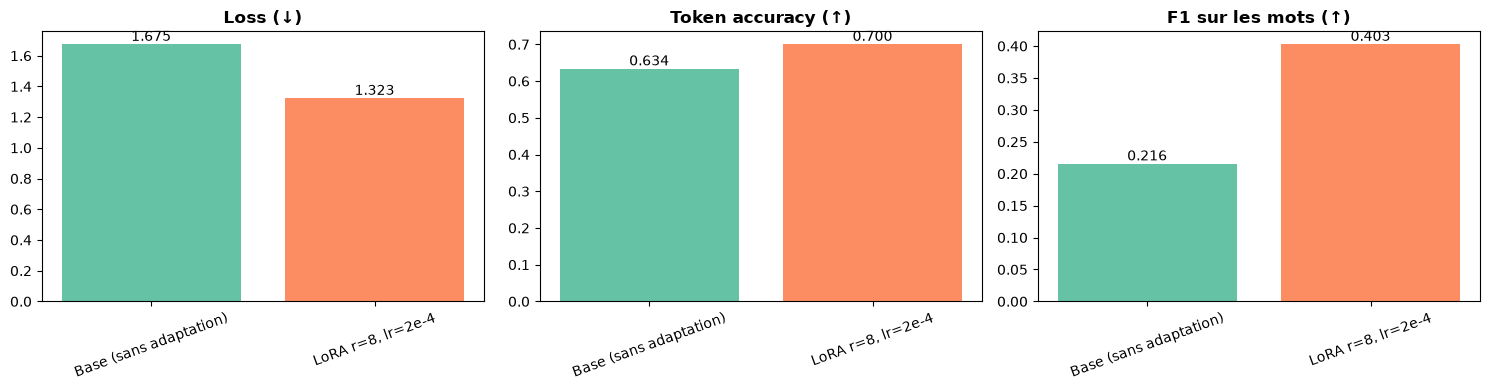

In [8]:
metrics = [m for m in ["loss", "token_acc", "F1"] if m in global_table.columns]
titles = {"loss": "Loss (↓)", "token_acc": "Token accuracy (↑)", "F1": "F1 sur les mots (↑)"}

fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 4))
axes = [axes] if len(metrics) == 1 else axes
for ax, m in zip(axes, metrics):
    bars = ax.bar(global_table.index, global_table[m], color=plt.cm.Set2.colors[: len(global_table)])
    ax.set_title(titles[m], fontweight="bold")
    ax.bar_label(bars, fmt="%.3f")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "eval_global.png", dpi=150)
plt.show()

## 7. Résultats par type

Les types ne servent qu'à l'analyse : `action.valide`, `action.invalide`, `action.incohérente`, `action.ambiguë`, `exploration`, `fin`, `début`, `énonciation`.
Attention aux types avec très peu d'exemples (`n` petit) : leurs scores sont peu fiables.

In [9]:
by_type = {}
for name, df in all_results.items():
    by_type[name] = pd.DataFrame({t: summarize(g) for t, g in df.groupby("type")}).T

types = by_type[base_name].index
counts = by_type[base_name]["n"].astype(int)

for m in metrics:
    tab = pd.DataFrame({name: by_type[name][m] for name in by_type})
    tab.insert(0, "n", counts)
    tab.loc["MACRO (moyenne des types)"] = [counts.sum()] + [tab[name].mean() for name in by_type]
    print(f"\n=== {titles[m]} par type ===")
    display(tab.round(3))
    tab.to_csv(RESULTS_DIR / f"eval_by_type_{m}.csv")


=== Loss (↓) par type ===


,n,Base (sans adaptation),"LoRA r=8, lr=2e-4"
action.ambiguë,6.0,1.366,1.167
action.incohérente,13.0,1.465,1.190
action.invalide,12.0,1.377,1.042
action.valide,31.0,1.799,1.398
début,2.0,1.559,1.012
exploration,14.0,1.722,1.241
fin,7.0,1.916,1.704
énonciation,4.0,1.972,1.763
MACRO (moyenne des types),89.0,1.647,1.315



=== Token accuracy (↑) par type ===


,n,Base (sans adaptation),"LoRA r=8, lr=2e-4"
action.ambiguë,6.0,0.692,0.723
action.incohérente,13.0,0.696,0.739
action.invalide,12.0,0.701,0.763
action.valide,31.0,0.593,0.675
début,2.0,0.661,0.759
exploration,14.0,0.639,0.722
fin,7.0,0.581,0.633
énonciation,4.0,0.575,0.617
MACRO (moyenne des types),89.0,0.642,0.704



=== F1 sur les mots (↑) par type ===


,n,Base (sans adaptation),"LoRA r=8, lr=2e-4"
action.ambiguë,6.0,0.217,0.357
action.incohérente,13.0,0.272,0.500
action.invalide,12.0,0.209,0.536
action.valide,31.0,0.211,0.352
début,2.0,0.119,0.471
exploration,14.0,0.208,0.468
fin,7.0,0.200,0.201
énonciation,4.0,0.187,0.242
MACRO (moyenne des types),89.0,0.203,0.391


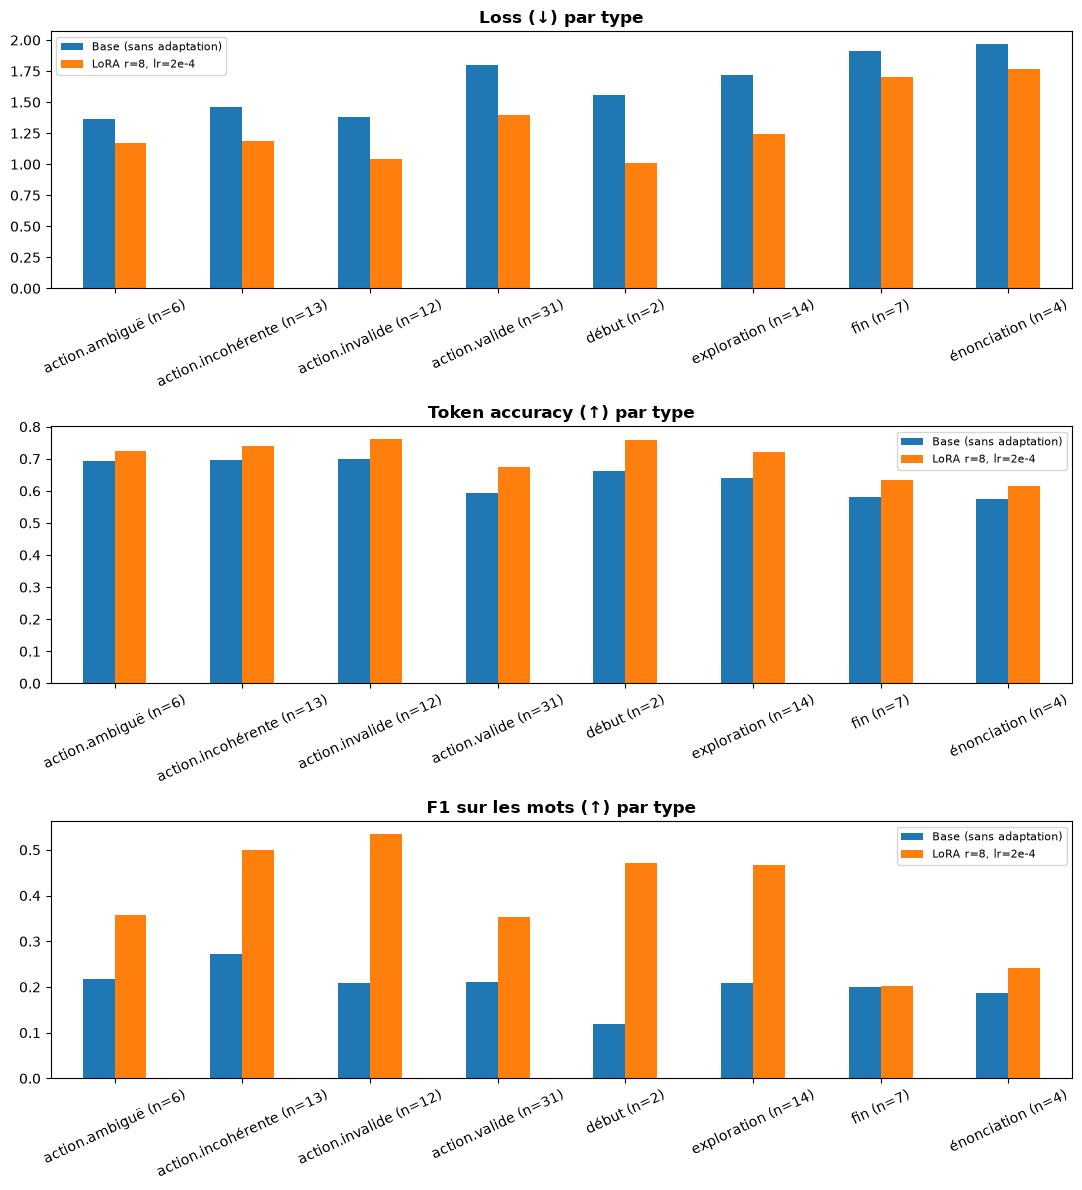

In [10]:
fig, axes = plt.subplots(len(metrics), 1, figsize=(11, 4 * len(metrics)))
axes = [axes] if len(metrics) == 1 else axes
for ax, m in zip(axes, metrics):
    tab = pd.DataFrame({name: by_type[name][m] for name in by_type})
    tab.index = [f"{t} (n={counts[t]})" for t in tab.index]
    tab.plot.bar(ax=ax, rot=25)
    ax.set_title(titles[m] + " par type", fontweight="bold")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "eval_by_type.png", dpi=150)
plt.show()

## 8. Analyse des exemples (pour le rapport)

On affiche les cas où l'adaptateur améliore ou dégrade le plus le F1 par rapport à la base, et quelques exemples tirés au hasard.
Utile pour commenter au moins 5 réussites ou erreurs.

In [11]:
if RUN_GENERATION:
    first_adapter = list(ADAPTERS)[0]
    a = all_results[base_name].set_index("idx")
    b = all_results[first_adapter].set_index("idx")
    cmp = pd.DataFrame({
        "type": a["type"],
        "f1_base": a["f1"], "f1_lora": b["f1"],
        "gain": b["f1"] - a["f1"],
        "reference": a["reference"],
        "pred_base": a["prediction"], "pred_lora": b["prediction"],
    })
    ctx_last_user = {r["idx"]: r["context"][-1]["content"] for r in records}
    cmp["dernier_message"] = cmp.index.map(ctx_last_user)

    def show(df, title):
        print("=" * 90); print(title); print("=" * 90)
        for idx, row in df.iterrows():
            print(f"[#{idx}] type={row['type']} | F1 base={row['f1_base']:.2f} → LoRA={row['f1_lora']:.2f}")
            print("  Joueur    :", str(row["dernier_message"])[:250])
            print("  Attendu   :", row["reference"][:350])
            print("  Base      :", row["pred_base"][:350])
            print("  LoRA      :", row["pred_lora"][:350])
            print()

    show(cmp.nlargest(5, "gain"), f"Plus fortes améliorations ({first_adapter})")
    show(cmp.nsmallest(5, "gain"), f"Plus fortes dégradations ({first_adapter})")
    show(cmp.sample(min(5, len(cmp)), random_state=SEED), "Exemples aléatoires")

    cmp.to_csv(RESULTS_DIR / "eval_comparaison_exemples.csv", encoding="utf-8")

Plus fortes améliorations (LoRA r=8, lr=2e-4)
[#6] type=action.invalide | F1 base=0.05 → LoRA=0.68
  Joueur    : Vu que c'est mon jeu, j'ouvre le code source et je supprime le gouffre de la carte pour marcher tranquillement.
  Attendu   : *Action refusée.* Vous ne pouvez pas modifier la réalité ni briser le 4ème mur. Vous êtes un aventurier physiquement présent devant ce gouffre bien réel et le vent continue de hurler. Que faites-vous ?
A) Vous traversez le pont lentement, en vous accrochant fermement aux cordes.
B) Vous cherchez un autre chemin en longeant le bord du gouffre.
C) Vo
  Base      : Ah, très astucieux ! Mais cela pourrait avoir des conséquences imprévues. Qu'en pensez-vous ?
  LoRA      : Les jeux vidéo n'existent pas dans cet univers médiéval-fantastique ! Le pont reste là, brisé et dangereux. Vous devez trouver un moyen de traverser. Que faites-vous ?
A) Vous traversez le pont lentement, en vous accrochant fermement aux cordes.
B) Vous cherchez un autre chemin en longea

In [12]:
# Sauvegarde de toutes les prédictions (pour la grille d'évaluation humaine et le rapport)
cols = [c for c in ["model", "idx", "type", "n_tokens", "nll_sum", "n_correct", "f1", "prediction", "reference"] if c in results.columns]
results[cols].to_json(RESULTS_DIR / "eval_predictions.json", orient="records", force_ascii=False, indent=2)
print("Fichiers écrits dans", RESULTS_DIR)
for p in sorted(RESULTS_DIR.iterdir()):
    print(" -", p.name)

Fichiers écrits dans /content/NLP_narrative-game/results
 - eval_by_type.png
 - eval_by_type_F1.csv
 - eval_by_type_loss.csv
 - eval_by_type_token_acc.csv
 - eval_comparaison_exemples.csv
 - eval_global.csv
 - eval_global.png
 - eval_predictions.json
